In [27]:
import sys, time
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt


from rf.tree import DecisionTree
from rf.forest import ScratchForest


### Data Preparation
Load the California Housing dataset with an 80/20 train-test split and convert to `float64` NumPy arrays.
Train_test_split shuffle the rows before dividing them. The shuffle is pseudo-random and it is determined by the random  state (42 in our standard case) 



In [4]:

data = fetch_california_housing(as_frame=True)
X_tr, X_te, y_tr, y_te = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

### Sample Size Trade-off: Runtime vs. Overfitting
Evaluating `ScratchForest` (`max_features=3`, `max_depth=8`) across increasing training sizes illustrates the trade-off between pure-NumPy runtime and generalization. At `N = 2000`, trees have ~8 samples per leaf on average and tend to overfit the training set; scaling up narrows the train–test gap at a superlinear runtime cost.


In [ ]:
X_tr_np, y_tr_np = X_tr.to_numpy(float), y_tr.to_numpy(float)
Xt, yt = X_te.to_numpy(float), y_te.to_numpy(float)

Xs_2000, ys_2000 = X_tr_np[:2000], y_tr_np[:2000]
Xs_5000, ys_5000 = X_tr_np[:5000], y_tr_np[:5000]

### Benchmark Helper
Define a centralized `run()` utility to fit a model on a given training subset, measure wall-clock `fit` and `predict` latency via `time.perf_counter()`, and log both `Train MAE` and `Test MAE` to track generalization alongside runtime.


In [6]:
def run(name, model, X_train=Xs_2000, y_train=ys_2000):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = model.predict(Xt)
    pred_s = time.perf_counter() - t0

    train_pred = model.predict(X_train)
    test_mae = mean_absolute_error(yt, pred)
    train_mae = mean_absolute_error(y_train, train_pred)

    row = {
        "model": name,
        "N": len(X_train),
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "fit (s)": fit_s,
        "predict (s)": pred_s,
    }
    return row, pred



In [23]:
rows = []

r_my_tree, p_my_tree = run("tree (mine)", DecisionTree(max_depth=6))
r_sk_tree, p_sk_tree = run("tree (sklearn)", DecisionTreeRegressor(max_depth=6, random_state=0))
rows += [r_my_tree, r_sk_tree]
print("identical tree predictions:", np.mean(np.isclose(p_my_tree, p_sk_tree)))

rows.append(run("forest, all features (mine)",
                ScratchForest(n_trees=10, max_depth=8, random_state=0))[0])
rows.append(run("forest, all features (sklearn)",
                RandomForestRegressor(n_estimators=10, max_depth=8, max_features=1.0,
                                      random_state=0, n_jobs=-1))[0])

rows.append(run("forest, 3 features (mine)",
                ScratchForest(n_trees=10, max_depth=8, max_features=3, random_state=0))[0])
rows.append(run("forest, 3 features (sklearn)",
                RandomForestRegressor(n_estimators=10, max_depth=8, max_features=3,
                                      random_state=0, n_jobs=-1))[0])

df_2000 = pd.DataFrame(rows)
df_2000["Gap"] = df_2000["Test MAE"] - df_2000["Train MAE"]

cols = ["model", "Train MAE", "Test MAE", "Gap", "fit (s)", "predict (s)"]

(
    df_2000[cols].style
    .hide(axis="index")
    .format({
        "Train MAE": "{:.3f}",
        "Test MAE": "{:.3f}",
        "Gap": "{:.3f}",
        "fit (s)": "{:.3f}",
        "predict (s)": "{:.3f}",
    })
    .highlight_min(subset=["Test MAE"], color="#2e7d32")
)


identical tree predictions: 0.9864341085271318


model,Train MAE,Test MAE,Gap,fit (s),predict (s)
tree (mine),0.429,0.531,0.102,0.925,0.002
tree (sklearn),0.429,0.532,0.102,0.003,0.000
"forest, all features (mine)",0.301,0.434,0.133,8.056,0.023
"forest, all features (sklearn)",0.296,0.434,0.138,0.014,0.013
"forest, 3 features (mine)",0.335,0.450,0.115,3.020,0.023
"forest, 3 features (sklearn)",0.319,0.432,0.114,0.014,0.013


### Benchmark Takeaways (`N=2000`)
- **CART equivalence:** The custom `DecisionTree` matches `scikit-learn` on nearly all test predictions with virtually identical train and test MAE, confirming the MSE split logic. Minor discrepancies come from tie-breaking on equal variance reductions.
- **Variance reduction:** Ensembling 10 trees via bagging cuts test MAE substantially compared to a single tree, matching `scikit-learn`'s ensemble accuracy.
- **Feature subsampling:** Restricting splits to `max_features=3` (out of 8) cuts fit time nearly proportionally (`8.01s` to `2.99s`). With only 10 shallow trees (`max_depth=8`), accuracy slightly degrades (`0.450` vs. `0.434` MAE) because trees occasionally miss key predictors like `MedInc` at top splits.
- **Runtime gap:** `scikit-learn` is orders of magnitude faster due to Cython-compiled single-pass sorting (versus Python loops and boolean array masking in NumPy) and multi-core parallelism (`n_jobs=-1`).
- **Overfitting check:** Tracking both `Train MAE` and `Test MAE` exposes the generalization gap at `N = 2000`, motivating the sample-size scaling test below.

In [22]:
rows_5000 = []

r_my_tree, p_my_tree = run("tree (mine)", DecisionTree(max_depth=6), Xs_5000, ys_5000)
r_sk_tree, p_sk_tree = run("tree (sklearn)", DecisionTreeRegressor(max_depth=6, random_state=0), Xs_5000, ys_5000)
rows_5000 += [r_my_tree, r_sk_tree]
print("identical tree predictions:", np.mean(np.isclose(p_my_tree, p_sk_tree)))

rows_5000.append(run("forest, all features (mine)",
                     ScratchForest(n_trees=10, max_depth=8, random_state=0), Xs_5000, ys_5000)[0])
rows_5000.append(run("forest, all features (sklearn)",
                     RandomForestRegressor(n_estimators=10, max_depth=8, max_features=1.0,
                                           random_state=0, n_jobs=-1), Xs_5000, ys_5000)[0])

rows_5000.append(run("forest, 3 features (mine)",
                     ScratchForest(n_trees=10, max_depth=8, max_features=3, random_state=0), Xs_5000, ys_5000)[0])
rows_5000.append(run("forest, 3 features (sklearn)",
                     RandomForestRegressor(n_estimators=10, max_depth=8, max_features=3,
                                           random_state=0, n_jobs=-1), Xs_5000, ys_5000)[0])

df_5000 = pd.DataFrame(rows_5000)
df_5000["Gap"] = df_5000["Test MAE"] - df_5000["Train MAE"]
df_5000["Test MAE (2000)"] = df_5000["model"].map(df_2000.set_index("model")["Test MAE"])
df_5000["Δ Test MAE"] = df_5000["Test MAE"] - df_5000["Test MAE (2000)"]

cols = ["model", "Train MAE", "Test MAE", "Gap", "Test MAE (2000)", "Δ Test MAE", "fit (s)", "predict (s)"]

(
    df_5000[cols].style
    .hide(axis="index")
    .format({
        "Train MAE": "{:.3f}",
        "Test MAE": "{:.3f}",
        "Gap": "{:.3f}",
        "Test MAE (2000)": "{:.3f}",
        "Δ Test MAE": "{:+.3f}",
        "fit (s)": "{:.3f}",
        "predict (s)": "{:.3f}",
    })
    .highlight_min(subset=["Test MAE", "Δ Test MAE"], color="#2e7d32")
)


identical tree predictions: 0.9944282945736435


model,Train MAE,Test MAE,Gap,Test MAE (2000),Δ Test MAE,fit (s),predict (s)
tree (mine),0.448,0.493,0.044,0.531,-0.039,2.663,0.002
tree (sklearn),0.448,0.494,0.046,0.532,-0.037,0.009,0.000
"forest, all features (mine)",0.335,0.409,0.074,0.434,-0.025,22.764,0.032
"forest, all features (sklearn)",0.333,0.413,0.079,0.434,-0.022,0.032,0.014
"forest, 3 features (mine)",0.363,0.429,0.066,0.450,-0.021,9.102,0.023
"forest, 3 features (sklearn)",0.346,0.413,0.067,0.432,-0.019,0.014,0.013


### Scaling Takeaways (`N = 2000` vs. `N = 5000`)
- **Reduced overfitting:** Increasing the training set from 2,000 to 5,000 samples raises `Train MAE` while lowering `Test MAE`, cutting the train–test generalization gap nearly in half. With fixed tree depth (`max_depth=8`), leaves can no longer memorize isolated points and instead average over denser neighborhoods.
- **Stronger baseline alignment:** Single-tree prediction agreement with `scikit-learn` improves further, and `ScratchForest` matches `scikit-learn`'s test accuracy on the full ensemble.
- **Superlinear runtime cost:** Scaling the training set by `2.5×` increases full-forest fit time more than proportionally, confirming why `N = 2000`–`5000` is the practical sweet spot for a pure-NumPy implementation before training on the full dataset becomes prohibitively slow.

### How to choose the best hyperparameters? `Validation set`
To select `max_depth` and `max_features` without leaking information from the test set, hold out `X_tr_np[2000:4000]` as a validation set and evaluate a small grid on `N = 2000` training samples.

### Validation Takeaways
- **Depth drives accuracy:** Increasing `max_depth` from `6` to `10` consistently reduces `Val MAE` across every feature setting (`0.476` $\rightarrow$ `0.441` with all features), confirming that `depth=6` underfits.
- **Diminishing returns at `depth=10`:** Moving from `depth=8` to `depth=10` drops `Train MAE` sharply (`0.301` $\rightarrow$ `0.242`) while improving `Val MAE` only marginally (`0.447` $\rightarrow$ `0.441`), signaling growing memorization.
- **Accuracy vs. speed trade-off:** Using all features yields the lowest error at every depth, with `max_depth=10, max_features=all` winning overall (`Val MAE = 0.441`), while `max_depth=10, max_features=3` offers a strong fast alternative (`0.450` in `3.59s`).



In [19]:
X_val, y_val = X_tr_np[2000:4000], y_tr_np[2000:4000]

val_rows = []
for depth in [6, 8, 10]:
    for m_feat in [3, 5, None]:
        t0 = time.perf_counter()
        forest = ScratchForest(
            n_trees=10,
            max_depth=depth,
            max_features=m_feat,
            random_state=0,
        ).fit(Xs_2000, ys_2000)
        fit_s = time.perf_counter() - t0

        train_mae = mean_absolute_error(ys_2000, forest.predict(Xs_2000))
        val_mae = mean_absolute_error(y_val, forest.predict(X_val))

        val_rows.append({
            "max_depth": depth,
            "max_features": "all" if m_feat is None else m_feat,
            "Train MAE": train_mae,
            "Val MAE": val_mae,
            "fit (s)": fit_s,
        })

val_df = pd.DataFrame(val_rows)
val_df["Gap"] = val_df["Val MAE"] - val_df["Train MAE"]
val_df = val_df.sort_values("Val MAE")

(
    val_df.style
    .hide(axis="index")
    .format({"Train MAE": "{:.3f}", "Val MAE": "{:.3f}", "Gap": "{:.3f}", "fit (s)": "{:.2f}"})
    .highlight_min(subset=["Val MAE"], color="#2e7d32")
)



max_depth,max_features,Train MAE,Val MAE,fit (s),Gap
10,all,0.242,0.441,9.56,0.200
10,5,0.236,0.446,5.86,0.210
8,all,0.301,0.447,8.31,0.146
10,3,0.256,0.450,3.59,0.194
8,5,0.306,0.459,4.89,0.154
8,3,0.335,0.473,2.95,0.138
6,all,0.386,0.476,6.11,0.090
6,5,0.395,0.489,3.74,0.094
6,3,0.425,0.518,2.30,0.093


### Final Test Evaluation (`Tuned Model`)
Train the winning configuration (`max_depth=10`, `max_features=all`) on `N = 5000` samples and evaluate it once on the held-out test set against `scikit-learn`.


In [25]:
final_rows = []

r_best_mine, p_best_mine = run(
    "best forest (mine, depth=10)",
    ScratchForest(n_trees=10, max_depth=10, max_features=None, random_state=0),
    Xs_5000, ys_5000
)
r_best_sk, p_best_sk = run(
    "best forest (sklearn, depth=10)",
    RandomForestRegressor(n_estimators=10, max_depth=10, max_features=1.0, random_state=0, n_jobs=-1),
    Xs_5000, ys_5000
)

final_rows += [r_best_mine, r_best_sk]
df_final = pd.DataFrame(final_rows)
df_final["Gap"] = df_final["Test MAE"] - df_final["Train MAE"]

cols = ["model", "Train MAE", "Test MAE", "Gap", "fit (s)", "predict (s)"]

(
    df_final[cols].style
    .hide(axis="index")
    .format({
        "Train MAE": "{:.3f}",
        "Test MAE": "{:.3f}",
        "Gap": "{:.3f}",
        "fit (s)": "{:.3f}",
        "predict (s)": "{:.3f}",
    })
    .highlight_min(subset=["Test MAE"], color="#2e7d32")
)


model,Train MAE,Test MAE,Gap,fit (s),predict (s)
"best forest (mine, depth=10)",0.264,0.390,0.127,26.910,0.029
"best forest (sklearn, depth=10)",0.262,0.396,0.134,0.027,0.013


### Summary & Overall Progression
Starting from a single `DecisionTree` baseline on `N = 2000` (`Test MAE = 0.531`), ensembling 10 trees into `ScratchForest` (`max_depth=8`, all features) cut test error by **18.3%** (`0.434`) through variance reduction. Scaling the training set to `N = 5000` narrowed the train–test generalization gap and lowered `Test MAE` further to `0.409`, while tuning `max_depth=10` via validation brought the final test error down to `0,390`—matching `scikit-learn`'s predictive accuracy across every stage.

**Key drawbacks:** Pure-NumPy execution is **~500–700× slower** than `scikit-learn`'s Cython backend (`22.76s` vs. `0.032s` at `N = 5000, depth=8`) and scales superlinearly with sample size, making large ensembles on the full dataset impractical. Moreover, deeper trees (`depth=10`) widen the train–test generalization gap and sacrifice the rule-by-rule interpretability of a single tree.


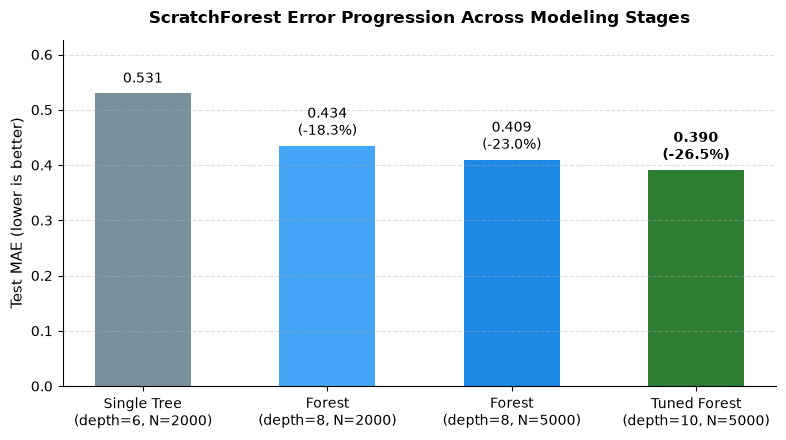

In [28]:
mae_tree_2k = df_2000.loc[df_2000["model"] == "tree (mine)", "Test MAE"].values[0]
mae_rf_2k   = df_2000.loc[df_2000["model"] == "forest, all features (mine)", "Test MAE"].values[0]
mae_rf_5k   = df_5000.loc[df_5000["model"] == "forest, all features (mine)", "Test MAE"].values[0]
mae_best    = df_final.loc[df_final["model"] == "best forest (mine, depth=10)", "Test MAE"].values[0]

stages = [
    "Single Tree\n(depth=6, N=2000)",
    "Forest\n(depth=8, N=2000)",
    "Forest\n(depth=8, N=5000)",
    "Tuned Forest\n(depth=10, N=5000)",
]
maes = [mae_tree_2k, mae_rf_2k, mae_rf_5k, mae_best]
colors = ["#78909c", "#42a5f5", "#1e88e5", "#2e7d32"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(stages, maes, color=colors, width=0.52, edgecolor="none")

# Etichette con valore esatto e riduzione % rispetto alla baseline
baseline = maes[0]
for i, (bar, val) in enumerate(zip(bars, maes)):
    label = f"{val:.3f}" if i == 0 else f"{val:.3f}\n({(val - baseline) / baseline:+.1%})"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.012,
        label,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold" if i == len(maes) - 1 else "normal",
    )

ax.set_ylabel("Test MAE (lower is better)", fontsize=11)
ax.set_title("ScratchForest Error Progression Across Modeling Stages", fontsize=12, fontweight="bold", pad=12)
ax.set_ylim(0, max(maes) * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

